# Shape hay Texture? Theo dõi cách ResNet-50 và ViT-B/16 ra quyết định

**Câu hỏi nghiên cứu.** Khi hình dạng tổng thể của một ảnh gợi ý vật A nhưng bề mặt lại gợi ý vật B, model tin tín hiệu nào hơn?

Notebook này là một bài thực hành đọc *behavior* của model, không phải đo accuracy. Ta bắt đầu bằng ảnh cue-conflict thật, theo dõi một ảnh đi qua ImageNet-1K và mapping chính thức 16 categories, rồi mới tổng hợp 1.200 ảnh xung đột cue. Mục tiêu là hiểu **bằng chứng nào** hỗ trợ kết luận và **bằng chứng nào chưa đủ** để kết luận.


In [1]:
from pathlib import Path
import os, sys, json
from collections import Counter

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import Markdown, display
from torchvision.models import ResNet50_Weights
from torchvision.transforms import functional as TF

from src.models import load_model
from experiments.shape_texture_bias.official_mapping import (
    CATEGORIES, OFFICIAL_16_INDICES, decisions_from_probabilities,
)
from experiments.shape_texture_bias.run_shape_texture_bias import (
    DATASET_ID, category_summary, run_model, seed_everything, summarize,
)

plt.style.use('seaborn-v0_8-whitegrid')
DECISION_COLORS = {'shape': '#2a9d8f', 'texture': '#e76f51', 'neither': '#6c757d'}
MODEL_COLORS = {'resnet50': '#386cb0', 'vit_b_16': '#7b3294'}
MODEL_LABELS = {'resnet50': 'ResNet-50', 'vit_b_16': 'ViT-B/16'}
OUT = ROOT / 'results' / 'tv4'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
seed_everything(42)
print('Thư mục project:', ROOT)
print('Thiết bị inference:', 'CUDA — ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')


/home/honganh/Documents/tempt/cnn-vit-interpretability/.deps/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Thư mục project: /home/honganh/Documents/tempt/cnn-vit-interpretability
Thiết bị inference: CUDA — NVIDIA GeForce RTX 3060


## Phần 1 — Trực giác: một ảnh, hai lời gợi ý

**Learning objective.** Phân biệt *shape* và *texture* trên ảnh thật trước khi xem model.

- **Shape** là hình dạng và cấu trúc tổng thể: thân, tư thế, các bộ phận và bố cục của đối tượng. Nó không chỉ là một đường viền mảnh.
- **Texture** là pattern, màu, chất liệu và chi tiết bề mặt cục bộ. Nó không chỉ là màu.
- Ở ảnh **cue-conflict**, style transfer khiến hai nguồn gợi ý này trỏ tới hai categories khác nhau. Một số ảnh cố ý có tính mơ hồ; ta không giả vờ rằng mọi người sẽ nhận ra chúng như nhau.

Bốn ví dụ dưới đây được cố định sau khi xem contact sheet vì chúng phủ các cặp cue khác nhau. `image_id` được hiển thị để việc chọn ví dụ minh bạch. Chúng chỉ phục vụ giải thích trực giác, **không** được dùng để suy ra kết quả định lượng.


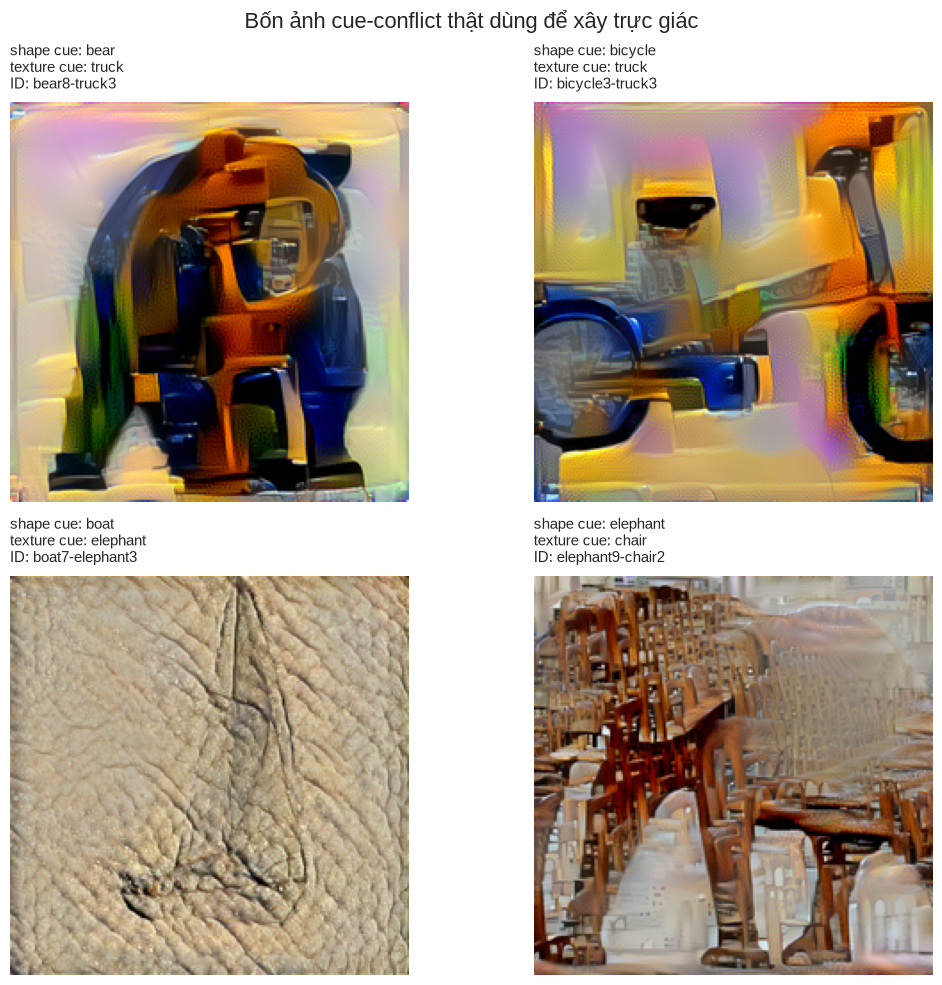

**Cách đọc hình:** hãy nhìn cấu trúc tổng thể trước, rồi nhìn pattern bề mặt. Nếu một cue chưa rõ với bạn, đó là một quan sát hợp lệ về độ mơ hồ của stimulus — không phải lý do để đổi nhãn benchmark.

In [2]:
dataset = load_dataset(DATASET_ID, split='test', token=False)
records = [dataset[i] for i in range(len(dataset))]
record_by_id = {record['file_id']: record for record in records}
valid_conflict = [record for record in records if record['shape_cue'] != record['texture_cue']]

# Ví dụ cố định, đa dạng; không được dùng để tính metric.
EXPLANATION_IMAGE_IDS = ['bear8-truck3', 'bicycle3-truck3', 'boat7-elephant3', 'elephant9-chair2']
explanation_records = [record_by_id[image_id] for image_id in EXPLANATION_IMAGE_IDS]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, record in zip(axes.flat, explanation_records):
    ax.imshow(record['image'])
    ax.axis('off')
    ax.set_title(
        f"shape cue: {record['shape_cue']}\ntexture cue: {record['texture_cue']}\nID: {record['file_id']}",
        fontsize=11, loc='left', pad=10,
    )
fig.suptitle('Bốn ảnh cue-conflict thật dùng để xây trực giác', fontsize=16, y=0.98)
fig.tight_layout()
plt.show()

display(Markdown(
    '**Cách đọc hình:** hãy nhìn cấu trúc tổng thể trước, rồi nhìn pattern bề mặt. '
    'Nếu một cue chưa rõ với bạn, đó là một quan sát hợp lệ về độ mơ hồ của stimulus — không phải lý do để đổi nhãn benchmark.'
))


### Một giả thuyết có thể kiểm tra

Trước khi chạy model, bạn có thể đoán: liệu ResNet-50 sẽ thường chọn texture hơn, hay ViT-B/16 sẽ thường chọn shape hơn? Đây chỉ là **giả thuyết**, không phải quy luật kiến trúc. Ta sẽ kiểm tra nó trên toàn bộ benchmark thay vì biến vài ảnh minh hoạ thành kết luận.


## Phần 2 — Hiểu dữ liệu trước khi hiểu kết quả

**Learning objective.** Biết benchmark có bao nhiêu ảnh, nhãn được tổ chức ra sao, và vì sao grid đa dạng quan trọng.

Tập Geirhos có 1.280 ảnh và 16 cue categories. Các ảnh có `shape cue == texture cue` không có xung đột nên sẽ bị loại khỏi Shape Bias; các ảnh còn lại là cue-conflict hợp lệ. Grid chọn có tính quyết định: một ảnh ở mỗi *shape category* với texture khác nhau, thay vì lấy 10 ảnh đầu tiên có thể cùng category.


Tổng số ảnh: 1,280
Cue-conflict hợp lệ: 1,200
Số cue categories: 16


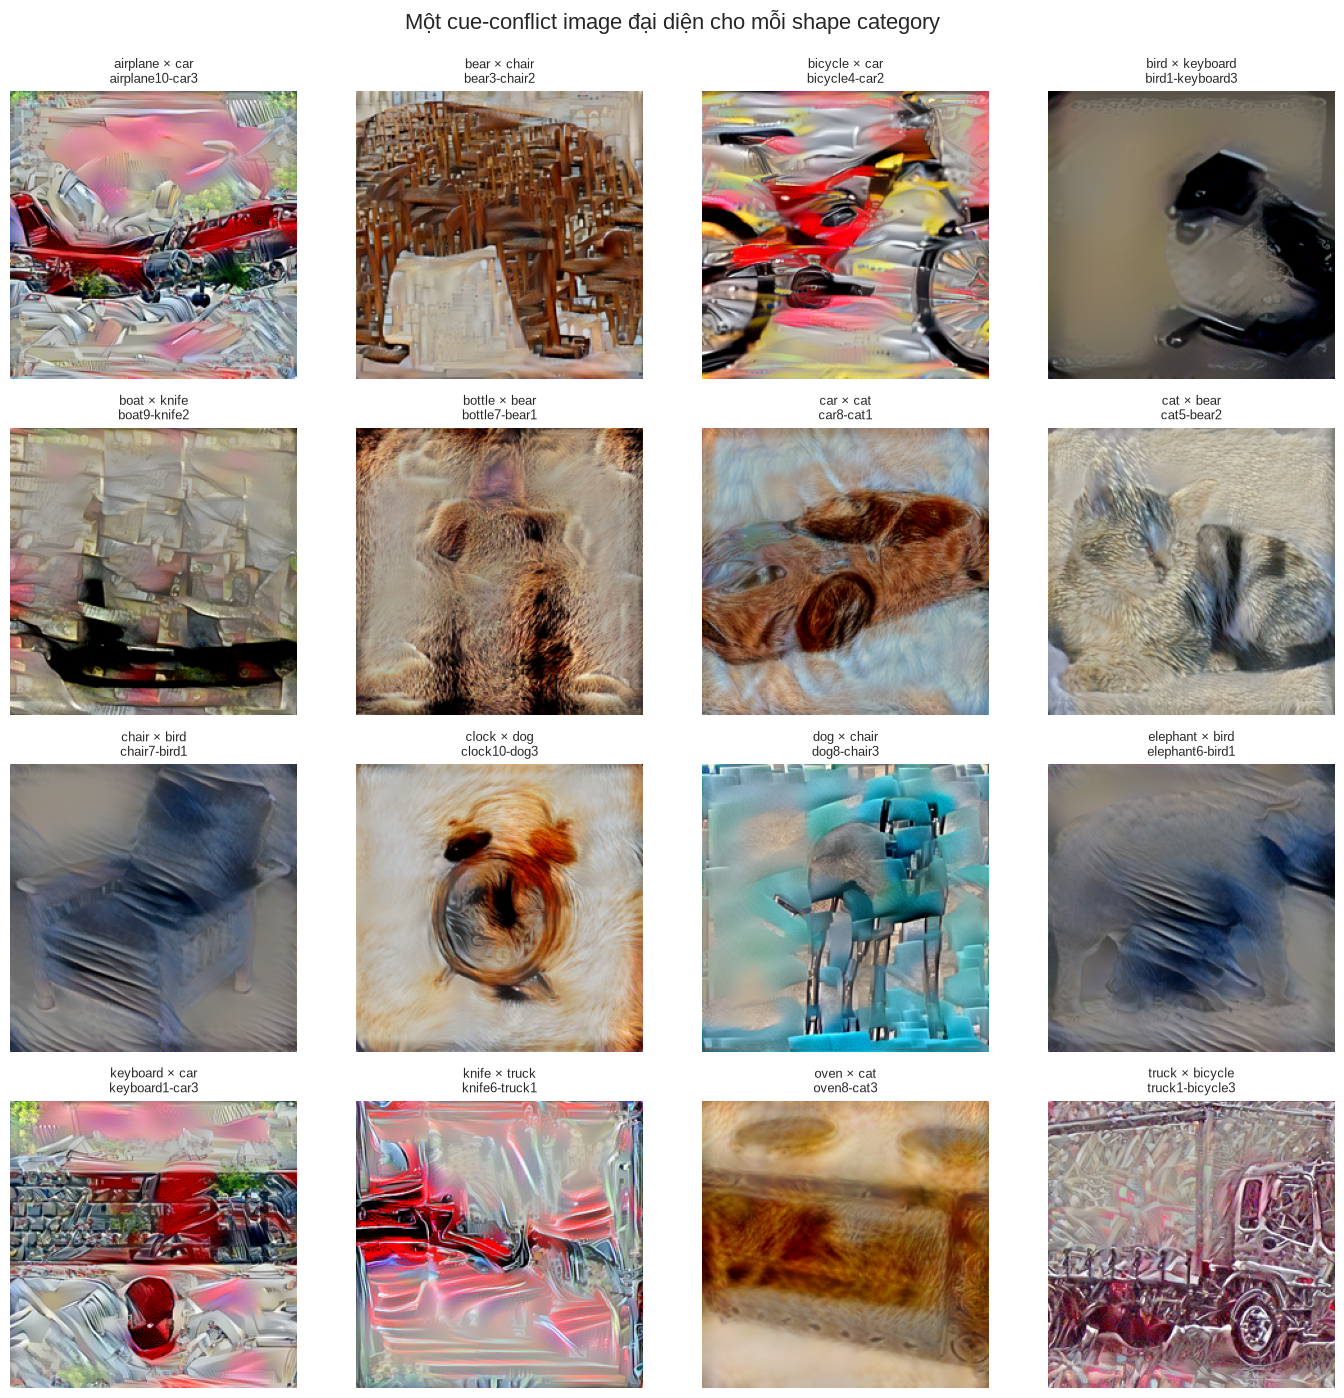

,airplane,bear,bicycle,bird,boat,bottle,car,cat,chair,clock,dog,elephant,keyboard,knife,oven,truck
shape cue,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80
texture cue,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80,80


**Quan sát:** hai tập nhãn có phân bố cân bằng theo category. Vì vậy, sự khác biệt sau này không thể được giải thích đơn giản bằng việc một cue category xuất hiện nhiều hơn hẳn.

In [3]:
all_categories = sorted({record['shape_cue'] for record in records})
# Mỗi shape category lấy một vị trí xác định khác nhau trong danh sách candidate để grid có texture đa dạng.
diverse_records = []
for index, category in enumerate(all_categories):
    candidates = [r for r in valid_conflict if r['shape_cue'] == category]
    diverse_records.append(candidates[(index * 7 + 3) % len(candidates)])

print(f'Tổng số ảnh: {len(records):,}')
print(f'Cue-conflict hợp lệ: {len(valid_conflict):,}')
print(f'Số cue categories: {len(all_categories)}')

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for ax, record in zip(axes.flat, diverse_records):
    ax.imshow(record['image'])
    ax.axis('off')
    ax.set_title(f"{record['shape_cue']} × {record['texture_cue']}\n{record['file_id']}", fontsize=9)
fig.suptitle('Một cue-conflict image đại diện cho mỗi shape category', fontsize=16, y=0.995)
fig.tight_layout()
plt.show()

label_counts = pd.DataFrame({
    'shape cue': Counter(record['shape_cue'] for record in records),
    'texture cue': Counter(record['texture_cue'] for record in records),
}).fillna(0).astype(int).sort_index()
display(label_counts.T)

display(Markdown(
    '**Quan sát:** hai tập nhãn có phân bố cân bằng theo category. Vì vậy, sự khác biệt sau này không thể được giải thích đơn giản bằng việc một cue category xuất hiện nhiều hơn hẳn.'
))


## Phần 3 — Hai model, một protocol đo lường

**Learning objective.** Phân biệt khác biệt kiến trúc với những thứ được giữ cố định trong phép đo.

Ta dùng loader chung của nhóm để không tự thay preprocessing hay weights. ResNet-50 và ViT-B/16 đều xuất 1.000 logits ImageNet, nhưng checkpoint khác nhau: ResNet dùng `ImageNet1K_V2`, còn ViT dùng `ImageNet1K_V1`. Đây là một **confounder**: kết quả mô tả đúng hai checkpoint này, không tách riêng được mọi ảnh hưởng của kiến trúc CNN/Transformer.


In [4]:
resnet, resnet_transform, resnet_meta = load_model('resnet50')
vit, vit_transform, vit_meta = load_model('vit_b_16')

setup = pd.DataFrame([
    {
        'Model': 'ResNet-50',
        'Pretrained checkpoint': resnet_meta['weights'],
        'Resize → crop': f"{resnet_meta['preprocessing']['resize_size']} → {resnet_meta['preprocessing']['crop_size']}",
        'Preprocessing': 'official torchvision transform',
        'Output space': '1.000 ImageNet classes',
    },
    {
        'Model': 'ViT-B/16',
        'Pretrained checkpoint': vit_meta['weights'],
        'Resize → crop': f"{vit_meta['preprocessing']['resize_size']} → {vit_meta['preprocessing']['crop_size']}",
        'Preprocessing': 'official torchvision transform',
        'Output space': '1.000 ImageNet classes',
    },
])
display(setup)


,Model,Pretrained checkpoint,Resize → crop,Preprocessing,Output space
0,ResNet-50,ResNet50_Weights.IMAGENET1K_V2,[232] → [224],official torchvision transform,1.000 ImageNet classes
1,ViT-B/16,ViT_B_16_Weights.IMAGENET1K_V1,[256] → [224],official torchvision transform,1.000 ImageNet classes


## Phần 4 — Theo một ảnh đi qua toàn bộ pipeline

**Learning objective.** Nhìn thấy cách một ảnh trở thành quyết định Shape / Texture / Neither.

Ta dùng một ảnh trong phần mở đầu. Hãy tự đoán trước: model nào, nếu có, sẽ chọn shape cue? Phần này không lấy ImageNet top-1 làm câu trả lời cuối cùng; protocol chính thức trước hết tổng hợp 1.000 scores thành 16 mapped category scores.

### Bước A–B: input và preprocessing

Hai checkpoint có resize khác nhau nhưng cùng center-crop 224×224. Hình dưới chỉ hiển thị ảnh sau resize/crop **trước normalization** để màu sắc còn đọc được; tensor đưa vào model sau đó vẫn dùng đúng transform chính thức, gồm normalization.


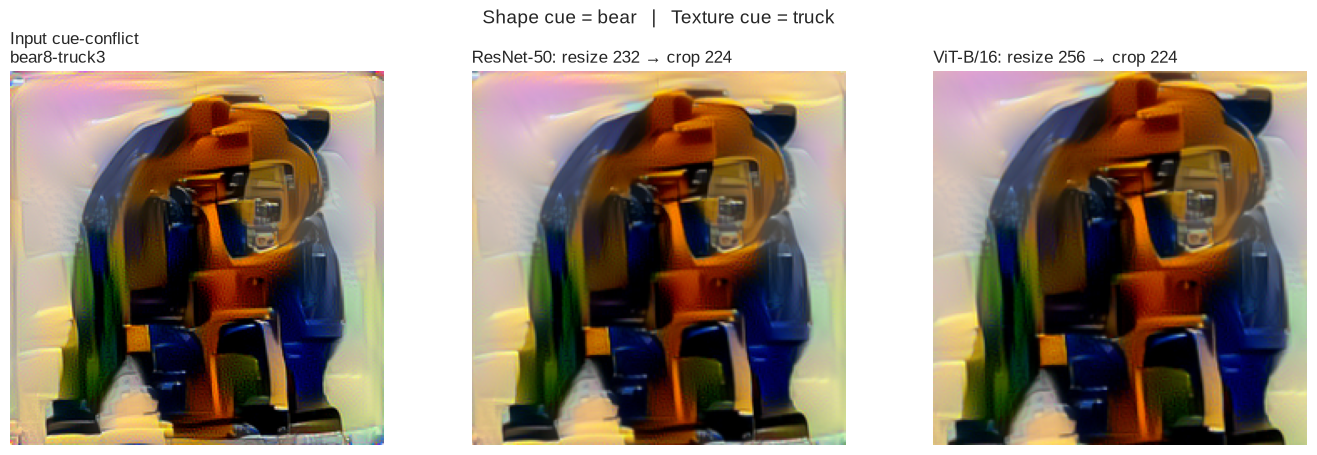

In [5]:
pipeline_record = record_by_id['bear8-truck3']

def show_preprocess_view(image, resize_size):
    resized = TF.resize(image.convert('RGB'), size=resize_size)
    return TF.center_crop(resized, output_size=[224, 224])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
axes[0].imshow(pipeline_record['image'])
axes[0].set_title('Input cue-conflict\n' + pipeline_record['file_id'], loc='left')
axes[1].imshow(show_preprocess_view(pipeline_record['image'], resnet_meta['preprocessing']['resize_size']))
axes[1].set_title('ResNet-50: resize 232 → crop 224', loc='left')
axes[2].imshow(show_preprocess_view(pipeline_record['image'], vit_meta['preprocessing']['resize_size']))
axes[2].set_title('ViT-B/16: resize 256 → crop 224', loc='left')
for ax in axes:
    ax.axis('off')
fig.suptitle(
    f"Shape cue = {pipeline_record['shape_cue']}   |   Texture cue = {pipeline_record['texture_cue']}",
    fontsize=14,
)
fig.tight_layout()
plt.show()


### Bước C: 1.000 ImageNet outputs không phải cue decision ngay lập tức

Cell này chạy **cùng một ảnh** qua cả hai model. Top-1 ImageNet chỉ để tham khảo. Cột “mapped category” mới là category 16 lớp dùng để so với shape cue và texture cue. “Mapped score” là **trung bình các softmax probabilities** của các ImageNet classes thuộc category đó; nó không phải xác suất chuẩn hoá trên 16 lớp.


In [6]:
imagenet_names = ResNet50_Weights.IMAGENET1K_V2.meta['categories']

def cue_decision(predicted_category, record):
    if predicted_category == record['shape_cue']:
        return 'shape'
    if predicted_category == record['texture_cue']:
        return 'texture'
    return 'neither'

def predict_one(model, transform, record):
    device = next(model.parameters()).device
    image_tensor = transform(record['image'].convert('RGB')).unsqueeze(0).to(device)
    with torch.inference_mode(), torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
        logits = model(image_tensor)
        probabilities = torch.softmax(logits.float(), dim=1).cpu().numpy()[0]
    category, winning_score = decisions_from_probabilities(probabilities)
    category_scores = {
        name: float(probabilities[OFFICIAL_16_INDICES[name]].mean())
        for name in CATEGORIES
    }
    top_index = int(probabilities.argmax())
    return {
        'imagenet_top1': imagenet_names[top_index],
        'imagenet_top1_probability': float(probabilities[top_index]),
        'predicted_category': category[0],
        'mapped_score': float(winning_score[0]),
        'decision': cue_decision(category[0], record),
        'category_scores': category_scores,
        'top5': [(int(index), imagenet_names[int(index)], float(probabilities[index]))
                 for index in probabilities.argsort()[-5:][::-1]],
    }

demo_predictions = {
    'resnet50': predict_one(resnet, resnet_transform, pipeline_record),
    'vit_b_16': predict_one(vit, vit_transform, pipeline_record),
}

prediction_cards = pd.DataFrame([
    {
        'Model': MODEL_LABELS[model],
        'ImageNet top-1 (tham khảo)': result['imagenet_top1'],
        'Mapped category (dùng để chấm cue)': result['predicted_category'],
        'Shape cue': pipeline_record['shape_cue'],
        'Texture cue': pipeline_record['texture_cue'],
        'Cue decision': result['decision'].title(),
        'Winning mapped score (mean softmax)': f"{result['mapped_score']:.5f}",
    }
    for model, result in demo_predictions.items()
])
display(prediction_cards)

display(Markdown(
    f"**Quan sát trên ảnh `{pipeline_record['file_id']}`:** ResNet-50 chọn **{demo_predictions['resnet50']['decision']}** "
    f"({demo_predictions['resnet50']['predicted_category']}), còn ViT-B/16 chọn **{demo_predictions['vit_b_16']['decision']}** "
    f"({demo_predictions['vit_b_16']['predicted_category']}). Đây mới là một trường hợp; phần sau kiểm tra toàn bộ benchmark."
))


,Model,ImageNet top-1 (tham khảo),Mapped category (dùng để chấm cue),Shape cue,Texture cue,Cue decision,Winning mapped score (mean softmax)
0,ResNet-50,refrigerator,bottle,bear,truck,Neither,0.01088
1,ViT-B/16,vacuum,bottle,bear,truck,Neither,0.00098


**Quan sát trên ảnh `bear8-truck3`:** ResNet-50 chọn **neither** (bottle), còn ViT-B/16 chọn **neither** (bottle). Đây mới là một trường hợp; phần sau kiểm tra toàn bộ benchmark.

### Bước D: minh hoạ mapping 1.000 → 16 theo từng bước

1. Model tạo 1.000 softmax scores ImageNet.
2. Mỗi cue category có một hoặc nhiều ImageNet classes trong mapping chính thức. Ví dụ `bear` có 4 indices, trong khi `dog` có rất nhiều breeds.
3. Với **mỗi** trong 16 categories, lấy *mean* score của các indices thuộc category đó.
4. Category có mean score lớn nhất thắng. Ta chỉ sau đó mới đối chiếu category thắng với hai cues của ảnh.

Hai bar chart sau hiển thị toàn bộ 16 mapped scores thật trên cùng ảnh. Màu xanh lá đánh dấu shape cue, cam đánh dấu texture cue, tím đánh dấu category thắng. Các cột không cộng thành 1, vì các groups có kích thước khác nhau và không tạo thành một phân phối 16 lớp.


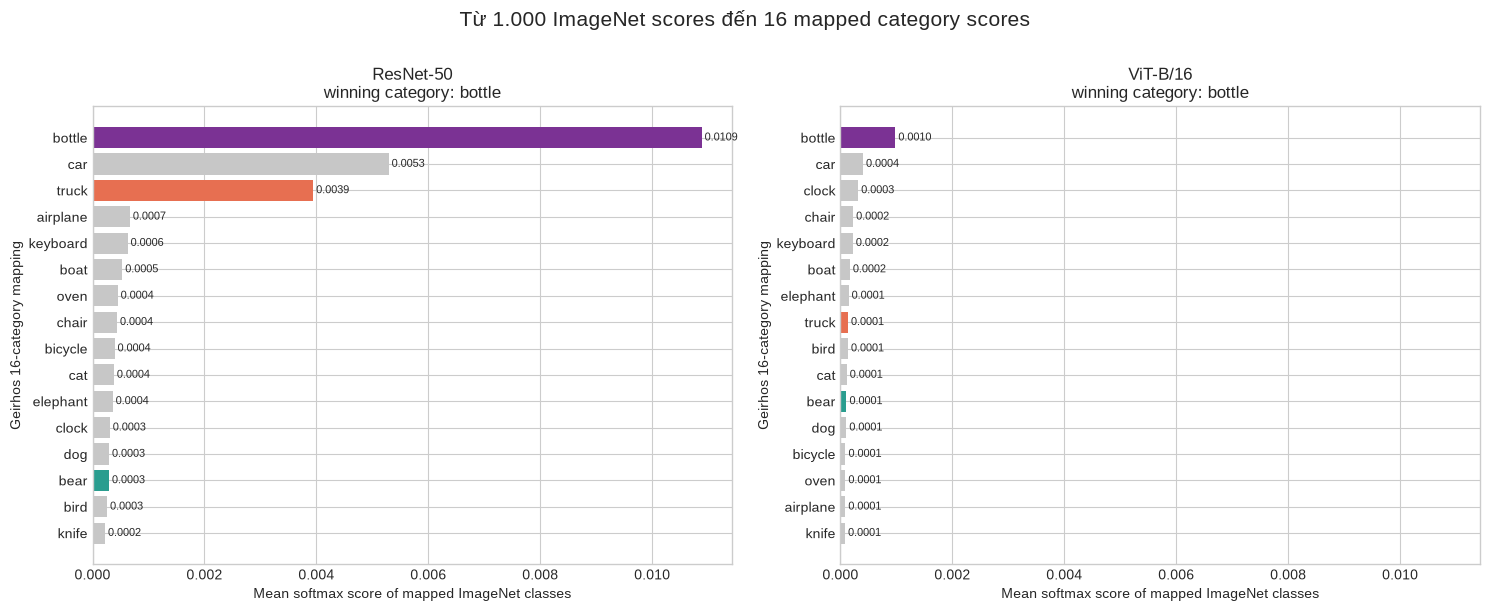

ResNet-50: 'bottle' gộp 7 ImageNet class(es); indices: [440, 720, 737, 898, 899, 901, 907]
  Top-5 ImageNet tham khảo: refrigerator (0.190); toaster (0.071); water jug (0.033); wine bottle (0.024); cab (0.019)
ViT-B/16: 'bottle' gộp 7 ImageNet class(es); indices: [440, 720, 737, 898, 899, 901, 907]
  Top-5 ImageNet tham khảo: vacuum (0.438); power drill (0.162); reel (0.050); pencil sharpener (0.047); hand blower (0.009)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, (model, result) in zip(axes, demo_predictions.items()):
    score_series = pd.Series(result['category_scores']).sort_values()
    bar_colors = []
    for category in score_series.index:
        if category == result['predicted_category']:
            bar_colors.append('#7b3294')
        elif category == pipeline_record['shape_cue']:
            bar_colors.append(DECISION_COLORS['shape'])
        elif category == pipeline_record['texture_cue']:
            bar_colors.append(DECISION_COLORS['texture'])
        else:
            bar_colors.append('#c7c7c7')
    ax.barh(score_series.index, score_series.values, color=bar_colors)
    ax.set_title(f"{MODEL_LABELS[model]}\nwinning category: {result['predicted_category']}")
    ax.set_xlabel('Mean softmax score of mapped ImageNet classes')
    ax.set_ylabel('Geirhos 16-category mapping')
    for y, value in enumerate(score_series.values):
        ax.text(value, y, f' {value:.4f}', va='center', fontsize=8)
fig.suptitle('Từ 1.000 ImageNet scores đến 16 mapped category scores', fontsize=15, y=1.01)
fig.tight_layout()
plt.show()

for model, result in demo_predictions.items():
    winner = result['predicted_category']
    mapped_indices = OFFICIAL_16_INDICES[winner]
    top_members = sorted(
        [(index, imagenet_names[index]) for index in mapped_indices],
        key=lambda pair: -next(prob for idx, _, prob in result['top5'] if idx == pair[0]) if pair[0] in [i for i, _, _ in result['top5']] else 0,
    )[:3]
    print(f"{MODEL_LABELS[model]}: '{winner}' gộp {len(mapped_indices)} ImageNet class(es); indices: {mapped_indices[:12]}" + (' ...' if len(mapped_indices) > 12 else ''))
    print('  Top-5 ImageNet tham khảo:', '; '.join(f'{name} ({prob:.3f})' for _, name, prob in result['top5']))


### Bước E: mini-conclusion

ImageNet top-1 và mapped decision có thể khác nhau: top-1 nhìn vào **một** ImageNet class có score cao nhất, còn protocol cue-conflict gộp các class liên quan trong mỗi human category. Vì vậy, “top-1 trông giống X” không đủ để gán Shape hay Texture. Câu hỏi kế tiếp là: liệu lựa chọn trên một ảnh có lặp lại trên hàng nghìn ảnh không?


## Phần 5 — Từ một decision đến Shape Bias

**Learning objective.** Đọc đúng mẫu số của Shape Bias, và phân biệt nó với coverage và accuracy.

| Mapped category so với cues | Decision | Ý nghĩa |
|---|---|---|
| bằng `shape cue` | Shape | Model chọn cue hình dạng |
| bằng `texture cue` | Texture | Model chọn cue bề mặt |
| không bằng cả hai | Neither | Model không chọn một trong hai cue benchmark |

\[
\mathrm{Shape\ Bias} = \frac{N_{\mathrm{shape}}}{N_{\mathrm{shape}} + N_{\mathrm{texture}}}.
\]

Ví dụ: 30 Shape, 70 Texture và 20 Neither decisions cho \(\mathrm{Shape\ Bias}=30/(30+70)=30\%\). **Neither không nằm trong mẫu số.** Cue-decision coverage lúc đó là \((30+70)/120=83.3\%\). Vì vậy Shape Bias không nói “30% mọi ảnh được nhận diện theo shape”, và cũng không phải accuracy.


In [8]:
prediction_path = OUT / 'shape_texture_predictions.csv'
metadata_path = OUT / 'shape_texture_metadata.json'
FORCE_RECOMPUTE = False  # Đổi thành True để chạy lại full inference thay vì dùng cache đã xác minh.

required_columns = {
    'image_id', 'shape_cue', 'texture_cue', 'model',
    'predicted_imagenet_label', 'predicted_category', 'category_confidence', 'decision',
}
expected_models = {'resnet50', 'vit_b_16'}
expected_record_labels = pd.DataFrame([
    {'image_id': r['file_id'], 'shape_cue': r['shape_cue'], 'texture_cue': r['texture_cue']}
    for r in records
])

def validate_prediction_cache():
    checks = []
    if not prediction_path.is_file() or not metadata_path.is_file():
        return False, None, pd.DataFrame([{'check': 'files exist', 'passed': False}])
    try:
        cached = pd.read_csv(prediction_path)
        metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    except (OSError, ValueError, json.JSONDecodeError):
        return False, None, pd.DataFrame([{'check': 'files are readable', 'passed': False}])

    checks.append(('required columns', required_columns <= set(cached.columns)))
    checks.append(('exactly two predictions per image', len(cached) == 2 * len(records)))
    checks.append(('two expected model names', set(cached['model']) == expected_models))
    checks.append(('unique (image_id, model)', cached[['image_id', 'model']].duplicated().sum() == 0))
    checks.append(('image IDs match dataset', set(cached['image_id']) == set(expected_record_labels['image_id'])))
    checks.append(('official mapping recorded', metadata.get('mapping') == 'Official Geirhos 16-category mean-softmax mapping'))
    checks.append(('evaluated image count recorded', metadata.get('evaluated_images') == len(records)))
    recorded_weights = {name: info.get('weights') for name, info in metadata.get('models', {}).items()}
    checks.append(('checkpoint metadata matches', recorded_weights == {'resnet50': resnet_meta['weights'], 'vit_b_16': vit_meta['weights']}))

    labels_ok = False
    decisions_ok = False
    if required_columns <= set(cached.columns):
        merged = cached.merge(expected_record_labels, on='image_id', suffixes=('', '_dataset'), how='left')
        labels_ok = (
            merged[['shape_cue_dataset', 'texture_cue_dataset']].notna().all().all()
            and (merged['shape_cue'] == merged['shape_cue_dataset']).all()
            and (merged['texture_cue'] == merged['texture_cue_dataset']).all()
        )
        expected_decision = np.where(
            merged['shape_cue'] == merged['texture_cue'], 'excluded_same_cue',
            np.where(merged['predicted_category'] == merged['shape_cue'], 'shape',
                     np.where(merged['predicted_category'] == merged['texture_cue'], 'texture', 'neither')),
        )
        decisions_ok = (merged['decision'].to_numpy() == expected_decision).all()
    checks.append(('cue labels match dataset', labels_ok))
    checks.append(('stored decisions match protocol', decisions_ok))
    check_frame = pd.DataFrame(checks, columns=['check', 'passed'])
    return bool(check_frame['passed'].all()), cached, check_frame

cache_ok, cached_predictions, cache_checks = validate_prediction_cache()
display(cache_checks)

if cache_ok and not FORCE_RECOMPUTE:
    predictions = cached_predictions
    print('Cache mode: dùng prediction cache đã vượt qua mọi kiểm tra ở trên.')
else:
    print('Recompute mode: cache không hợp lệ hoặc FORCE_RECOMPUTE=True; chạy lại full inference.')
    # Giải phóng hai model demo trước khi utility nạp model tuần tự.
    del resnet, vit
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    generated_rows, generated_metadata = [], {}
    for model_name in ('resnet50', 'vit_b_16'):
        rows, model_meta = run_model(records, model_name, batch_size=64, allow_download=True)
        generated_rows.extend(rows)
        generated_metadata[model_name] = model_meta
    predictions = pd.DataFrame(generated_rows)
    predictions.to_csv(prediction_path, index=False)
    metadata_path.write_text(json.dumps({
        'dataset': DATASET_ID,
        'evaluated_images': len(records),
        'mapping': 'Official Geirhos 16-category mean-softmax mapping',
        'models': generated_metadata,
    }, indent=2), encoding='utf-8')

print(f"Prediction records: {len(predictions):,}; unique image-model pairs: {predictions[['image_id', 'model']].drop_duplicates().shape[0]:,}")


,check,passed
0,required columns,True
1,exactly two predictions per image,True
2,two expected model names,True
3,"unique (image_id, model)",True
4,image IDs match dataset,True
5,official mapping recorded,True
6,evaluated image count recorded,True
7,checkpoint metadata matches,True
8,cue labels match dataset,True
9,stored decisions match protocol,True


Cache mode: dùng prediction cache đã vượt qua mọi kiểm tra ở trên.
Prediction records: 2,560; unique image-model pairs: 2,560


In [9]:
summary_rows = []
for model_name in ('resnet50', 'vit_b_16'):
    result = summarize(predictions[predictions['model'] == model_name].to_dict('records'), seed=42)
    summary_rows.append({'model': model_name, **result})
summary = pd.DataFrame(summary_rows).set_index('model')

# Paired bootstrap: cùng image IDs được resample đồng thời cho hai model.
def shape_bias_from_decisions(decisions):
    decisions = np.asarray(decisions)
    n_shape = (decisions == 'shape').sum()
    n_texture = (decisions == 'texture').sum()
    return n_shape / (n_shape + n_texture) if n_shape + n_texture else np.nan

def paired_bootstrap_difference(prediction_frame, n_bootstrap=4000, seed=42):
    paired = prediction_frame.pivot(index='image_id', columns='model', values='decision').loc[:, ['resnet50', 'vit_b_16']]
    values = paired.to_numpy()
    rng = np.random.default_rng(seed)
    differences = []
    for _ in range(n_bootstrap):
        sample = values[rng.integers(0, len(values), len(values))]
        resnet_bias = shape_bias_from_decisions(sample[:, 0])
        vit_bias = shape_bias_from_decisions(sample[:, 1])
        if np.isfinite(resnet_bias) and np.isfinite(vit_bias):
            differences.append(vit_bias - resnet_bias)
    return float(np.quantile(differences, .025)), float(np.quantile(differences, .975))

paired_ci_low, paired_ci_high = paired_bootstrap_difference(predictions)
summary_display = summary.reset_index().replace({'resnet50': 'ResNet-50', 'vit_b_16': 'ViT-B/16'})
for column in ['cue_decision_coverage', 'shape_bias', 'shape_bias_ci95_low', 'shape_bias_ci95_high']:
    summary_display[column] = (100 * summary_display[column]).map(lambda value: f'{value:.2f}%')
display(summary_display[[
    'model', 'num_valid_cue_conflict', 'shape_decisions', 'texture_decisions', 'neither_decisions',
    'cue_decision_coverage', 'shape_bias', 'shape_bias_ci95_low', 'shape_bias_ci95_high',
]])


,model,num_valid_cue_conflict,shape_decisions,texture_decisions,neither_decisions,cue_decision_coverage,shape_bias,shape_bias_ci95_low,shape_bias_ci95_high
0,ResNet-50,1200,181,671,348,71.00%,21.24%,18.52%,24.09%
1,ViT-B/16,1200,326,493,381,68.25%,39.80%,36.45%,43.12%


## Phần 6 — Kết quả trên toàn bộ benchmark

**Learning objective.** Đọc Shape Bias cùng số decisions và coverage, thay vì chỉ nhìn một phần trăm.

Hai biểu đồ dưới trả lời hai câu hỏi khác nhau. Biểu đồ đầu tiên dùng Shape Bias và 95% bootstrap CI. Biểu đồ thứ hai cho biết *bao nhiêu* Shape, Texture và Neither decisions tạo ra tỷ lệ đó. Cả hai cần thiết vì hai model có coverage khác nhau.

Khi so sánh hai model trên cùng ảnh, khoảng tin cậy quan trọng nhất cho chênh lệch là **paired bootstrap**: ở mỗi lần resample, cùng tập image IDs được dùng cho cả ResNet và ViT. Không suy ra chênh lệch chỉ từ việc hai CI riêng lẻ có chồng lấn hay không.


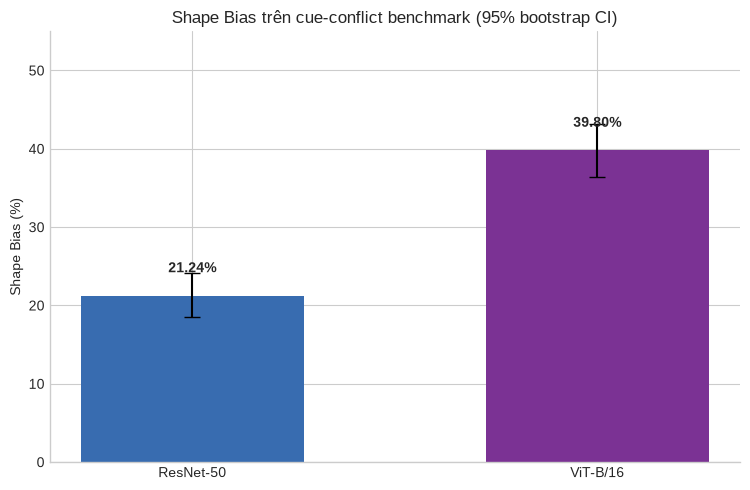

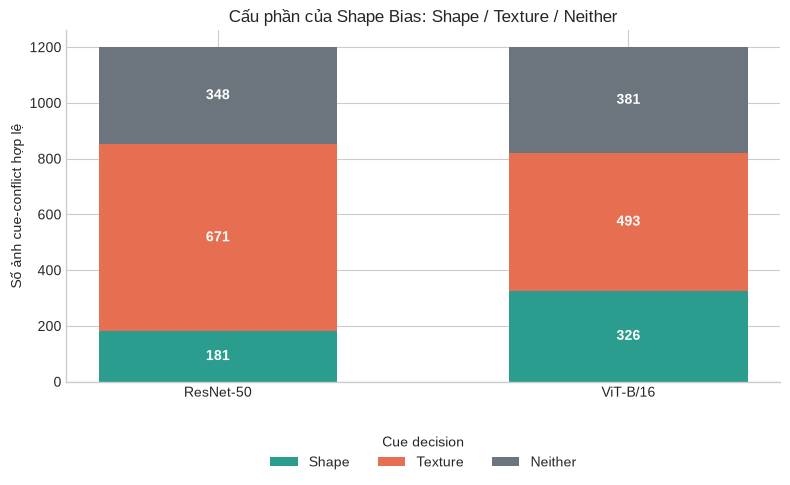

**Đọc hai biểu đồ cùng nhau.** ViT-B/16 có Shape Bias cao hơn ResNet-50 **18.56 percentage points** (39.80% so với 21.24%). Paired-bootstrap 95% CI cho chênh lệch ViT − ResNet là **[15.60, 21.66] pp**. Tuy vậy, Texture vẫn là quyết định nhiều nhất ở cả hai model; Neither cũng không hiếm. Coverage lần lượt là 71.00% và 68.25%, nên mẫu số Shape Bias không giống toàn bộ 1.200 ảnh theo cùng một cách.

In [10]:
model_order = ['resnet50', 'vit_b_16']
values = 100 * summary.loc[model_order, 'shape_bias'].to_numpy()
low = 100 * summary.loc[model_order, 'shape_bias_ci95_low'].to_numpy()
high = 100 * summary.loc[model_order, 'shape_bias_ci95_high'].to_numpy()

fig, ax = plt.subplots(figsize=(7.6, 5))
bars = ax.bar(
    [MODEL_LABELS[m] for m in model_order], values,
    yerr=np.vstack([values - low, high - values]), capsize=6,
    color=[MODEL_COLORS[m] for m in model_order], width=.55,
)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 3, f'{value:.2f}%', ha='center', weight='bold')
ax.set_ylim(0, 55)
ax.set_ylabel('Shape Bias (%)')
ax.set_title('Shape Bias trên cue-conflict benchmark (95% bootstrap CI)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / 'shape_bias_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
bottom = np.zeros(2)
for decision in ('shape', 'texture', 'neither'):
    counts = summary.loc[model_order, f'{decision}_decisions'].to_numpy()
    bars = ax.bar([MODEL_LABELS[m] for m in model_order], counts, bottom=bottom,
                  label=decision.title(), color=DECISION_COLORS[decision], width=.58)
    for bar, count, start in zip(bars, counts, bottom):
        if count >= 70:
            ax.text(bar.get_x() + bar.get_width()/2, start + count/2, str(int(count)),
                    ha='center', va='center', color='white', weight='bold')
    bottom += counts
ax.set_ylabel('Số ảnh cue-conflict hợp lệ')
ax.set_title('Cấu phần của Shape Bias: Shape / Texture / Neither')
ax.legend(title='Cue decision', ncol=3, loc='upper center', bbox_to_anchor=(.5, -0.12))
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / 'decision_stacked_bar.png', dpi=300, bbox_inches='tight')
plt.show()

resnet_bias = 100 * summary.loc['resnet50', 'shape_bias']
vit_bias = 100 * summary.loc['vit_b_16', 'shape_bias']
delta = vit_bias - resnet_bias
display(Markdown(
    f"**Đọc hai biểu đồ cùng nhau.** ViT-B/16 có Shape Bias cao hơn ResNet-50 **{delta:.2f} percentage points** "
    f"({vit_bias:.2f}% so với {resnet_bias:.2f}%). Paired-bootstrap 95% CI cho chênh lệch ViT − ResNet là "
    f"**[{100*paired_ci_low:.2f}, {100*paired_ci_high:.2f}] pp**. Tuy vậy, Texture vẫn là quyết định nhiều nhất ở cả hai model; "
    f"Neither cũng không hiếm. Coverage lần lượt là {100*summary.loc['resnet50','cue_decision_coverage']:.2f}% và "
    f"{100*summary.loc['vit_b_16','cue_decision_coverage']:.2f}%, nên mẫu số Shape Bias không giống toàn bộ 1.200 ảnh theo cùng một cách."
))


## Phần 7 — Khi nào hai model bất đồng?

**Learning objective.** Kết nối metric tổng hợp với các ảnh thật, mà không biến case study thành bằng chứng duy nhất.

Mỗi scenario dưới đây được xác định bằng decision records trước, sau đó chọn **một** ảnh có tổng mapped score của hai model cao nhất trong nhóm để phần chữ dễ đọc. `image_id`, cues và predictions đều hiện cạnh ảnh. Lựa chọn này không thay thế thống kê: số ở tiêu đề là toàn bộ số ảnh trong scenario.


/tmp/ipykernel_3724143/338689274.py:19: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  candidates['combined_mapped_score'] = (
/tmp/ipykernel_3724143/338689274.py:19: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  candidates['combined_mapped_score'] = (
/tmp/ipykernel_3724143/338689274.py:19: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  candidates['combined_mapped_score'] = (
/tmp/ipykernel_3724143/338689274.py:19: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tup

,Scenario,Số ảnh,Ví dụ ID
0,"ResNet chọn Texture, ViT chọn Shape",117,clock2-elephant2
1,"ResNet chọn Shape, ViT chọn Texture",15,bottle5-keyboard2
2,Cả hai chọn Shape,150,oven9-bird3
3,Cả hai chọn Texture,391,clock1-elephant2
4,Ít nhất một model chọn Neither,527,bicycle4-bottle1


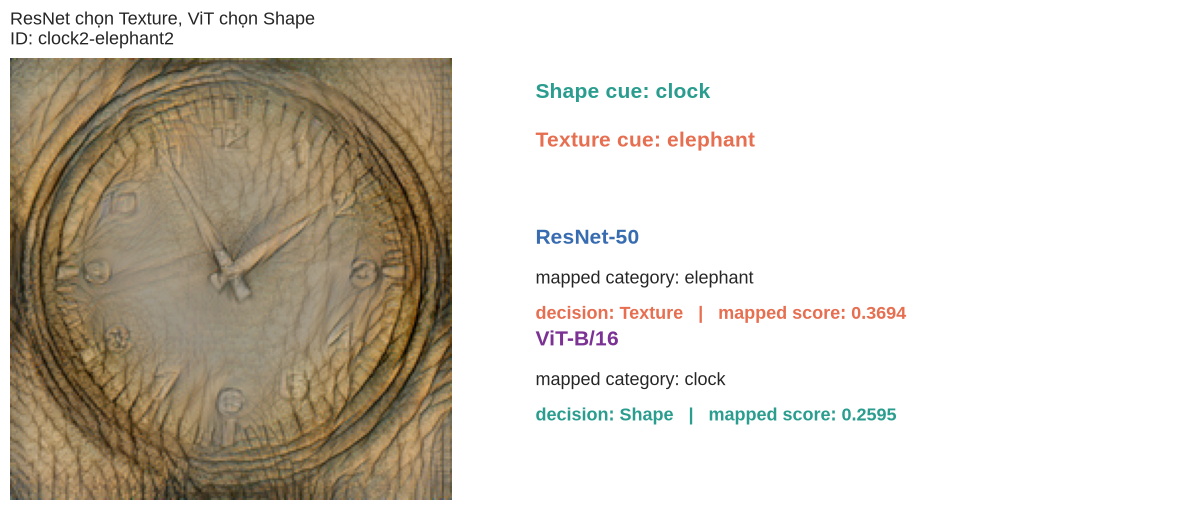

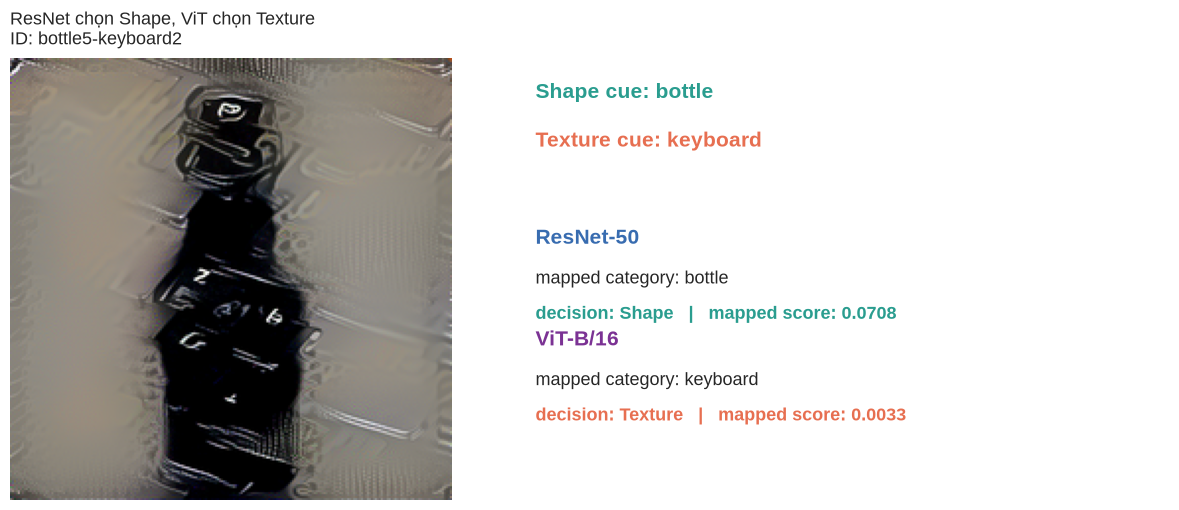

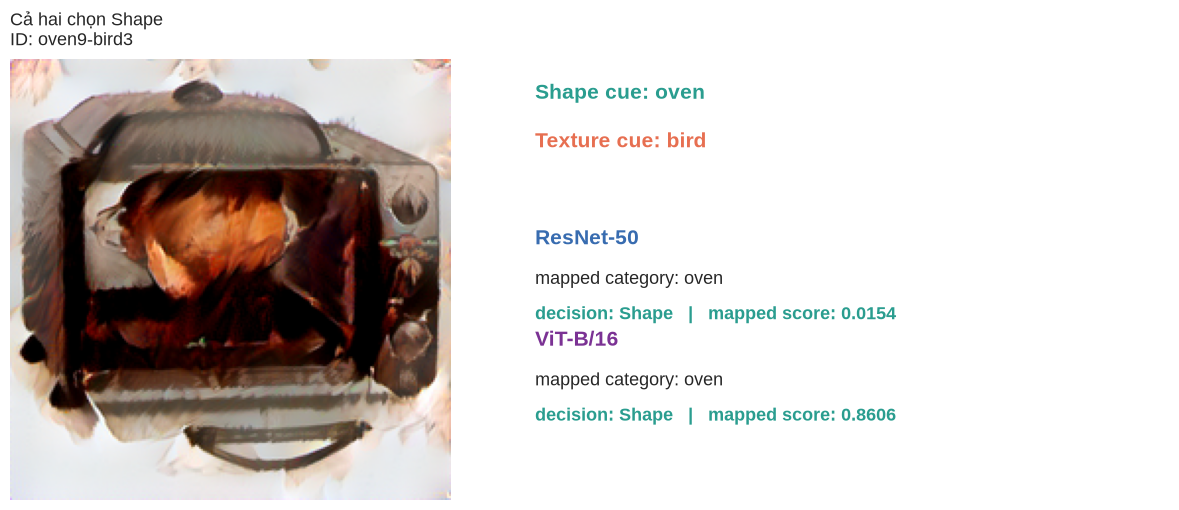

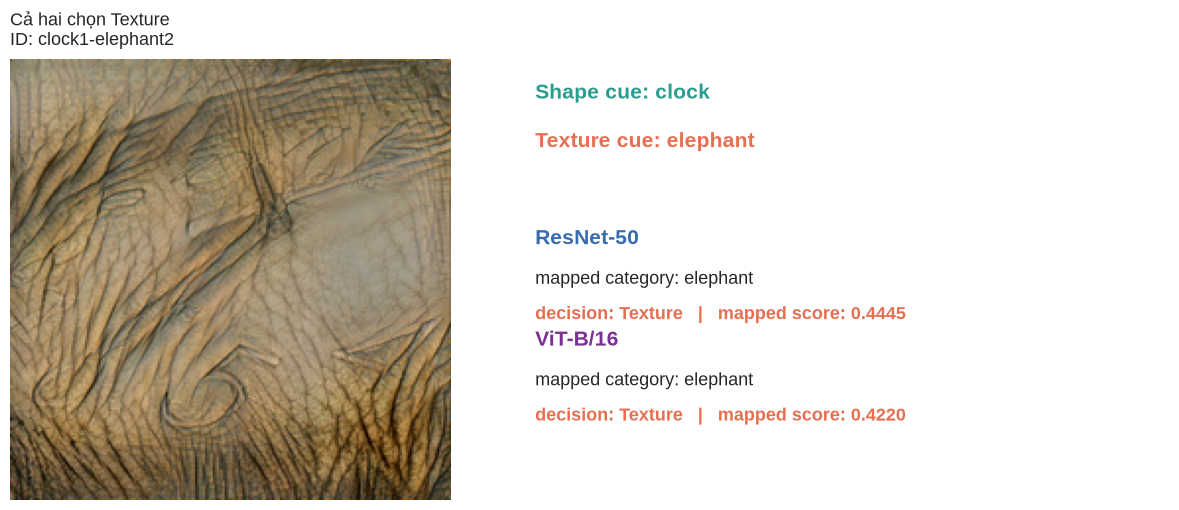

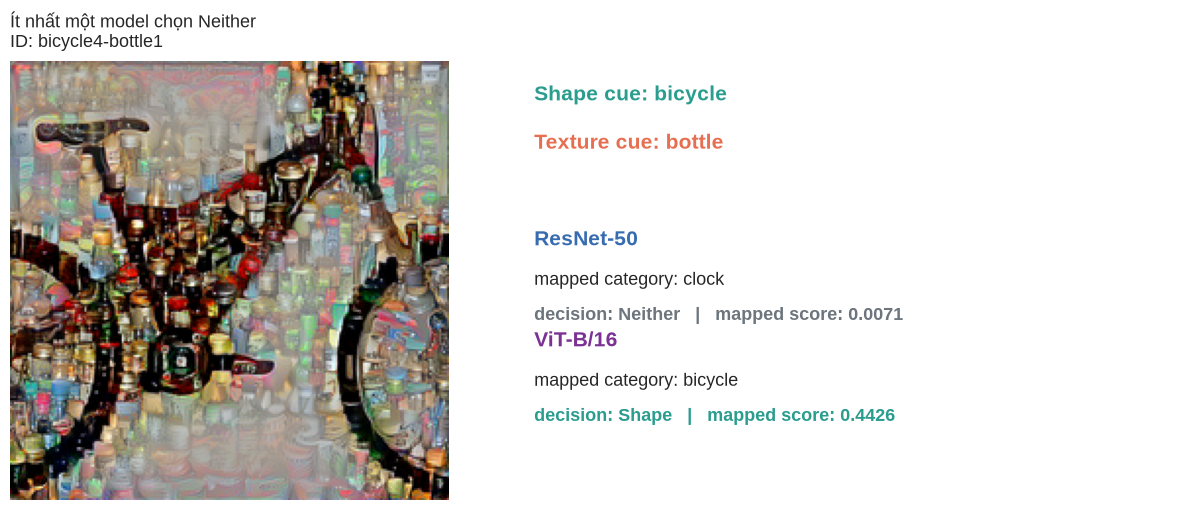

**Câu hỏi để suy nghĩ:** Vì sao ViT có Shape Bias tổng cao hơn nhưng vẫn chọn Texture ở nhiều ảnh? Vì Shape Bias là tỷ lệ có điều kiện trên các Shape + Texture decisions, không phải quy tắc cho từng ảnh. Ví dụ, ngay scenario ResNet Texture → ViT Shape có 117 ảnh, nhưng các scenario khác và Neither vẫn tồn tại. Các ảnh này mô tả *behavior quan sát được*; chúng không tự chứng minh cơ chế attention hay receptive field.

In [11]:
wide = predictions.pivot(index='image_id', columns='model', values=['decision', 'predicted_category', 'category_confidence'])
scenarios = [
    ('ResNet chọn Texture, ViT chọn Shape',
     (wide['decision']['resnet50'] == 'texture') & (wide['decision']['vit_b_16'] == 'shape')),
    ('ResNet chọn Shape, ViT chọn Texture',
     (wide['decision']['resnet50'] == 'shape') & (wide['decision']['vit_b_16'] == 'texture')),
    ('Cả hai chọn Shape',
     (wide['decision']['resnet50'] == 'shape') & (wide['decision']['vit_b_16'] == 'shape')),
    ('Cả hai chọn Texture',
     (wide['decision']['resnet50'] == 'texture') & (wide['decision']['vit_b_16'] == 'texture')),
    ('Ít nhất một model chọn Neither',
     (wide['decision']['resnet50'] == 'neither') | (wide['decision']['vit_b_16'] == 'neither')),
]

scenario_counts = []
selected_cases = []
for title, mask in scenarios:
    candidates = wide.loc[mask].copy()
    candidates['combined_mapped_score'] = (
        candidates[('category_confidence', 'resnet50')].astype(float)
        + candidates[('category_confidence', 'vit_b_16')].astype(float)
    )
    selected_id = candidates.sort_values('combined_mapped_score', ascending=False).index[0]
    scenario_counts.append({'Scenario': title, 'Số ảnh': len(candidates), 'Ví dụ ID': selected_id})
    selected_cases.append((title, selected_id))

display(pd.DataFrame(scenario_counts))

for title, image_id in selected_cases:
    record = record_by_id[image_id]
    row = wide.loc[image_id]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})
    axes[0].imshow(record['image'])
    axes[0].axis('off')
    axes[0].set_title(f"{title}\nID: {image_id}", loc='left', fontsize=13, pad=10)
    axes[1].axis('off')
    axes[1].text(.02, .91, f"Shape cue: {record['shape_cue']}", color=DECISION_COLORS['shape'], fontsize=15, weight='bold', transform=axes[1].transAxes)
    axes[1].text(.02, .80, f"Texture cue: {record['texture_cue']}", color=DECISION_COLORS['texture'], fontsize=15, weight='bold', transform=axes[1].transAxes)
    for line_index, model_name in enumerate(['resnet50', 'vit_b_16']):
        decision = row[('decision', model_name)]
        category = row[('predicted_category', model_name)]
        score = float(row[('category_confidence', model_name)])
        y = .58 - .23 * line_index
        axes[1].text(.02, y, MODEL_LABELS[model_name], color=MODEL_COLORS[model_name], fontsize=15, weight='bold', transform=axes[1].transAxes)
        axes[1].text(.02, y-.09, f"mapped category: {category}", fontsize=13, transform=axes[1].transAxes)
        axes[1].text(.02, y-.17, f"decision: {decision.title()}   |   mapped score: {score:.4f}",
                     color=DECISION_COLORS[decision], fontsize=13, weight='bold', transform=axes[1].transAxes)
    fig.tight_layout()
    plt.show()

texture_to_shape_count = scenario_counts[0]['Số ảnh']
display(Markdown(
    f"**Câu hỏi để suy nghĩ:** Vì sao ViT có Shape Bias tổng cao hơn nhưng vẫn chọn Texture ở nhiều ảnh? "
    f"Vì Shape Bias là tỷ lệ có điều kiện trên các Shape + Texture decisions, không phải quy tắc cho từng ảnh. "
    f"Ví dụ, ngay scenario ResNet Texture → ViT Shape có {texture_to_shape_count} ảnh, nhưng các scenario khác và Neither vẫn tồn tại. "
    f"Các ảnh này mô tả *behavior quan sát được*; chúng không tự chứng minh cơ chế attention hay receptive field."
))


## Phần 8 — Pattern có giữ trên các categories không?

**Learning objective.** Nhìn sự khác nhau theo shape cue mà không nhầm nó với class-wise accuracy.

Mỗi thanh là Shape Bias có điều kiện trong một shape category. Nhãn `n=R/V` là số cue decisions (Shape + Texture) trong mẫu số của ResNet/ViT; `n` nhỏ làm estimate kém ổn định hơn. Đây không phải accuracy theo class vì benchmark không chấm một nhãn ImageNet “đúng” duy nhất.


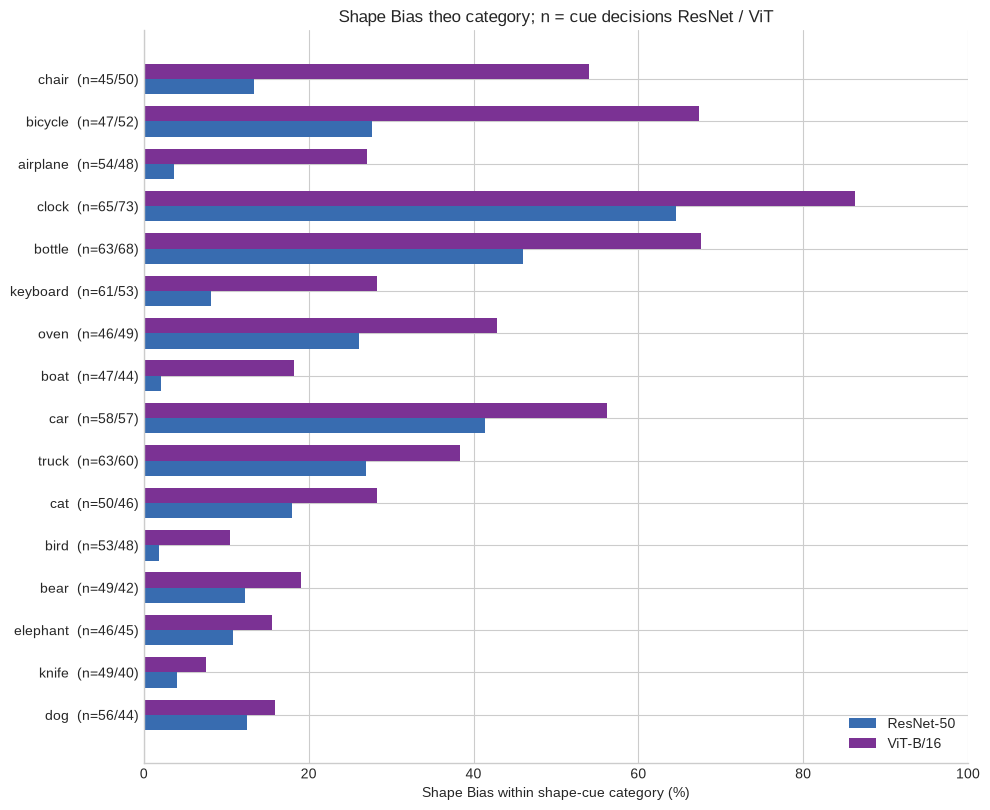

,shape cue,ResNet Shape Bias,ResNet n cue decisions,ViT Shape Bias,ViT n cue decisions,ViT − ResNet
10,dog,12.5%,56,15.9%,44,+3.4 pp
13,knife,4.1%,49,7.5%,40,+3.4 pp
11,elephant,10.9%,46,15.6%,45,+4.7 pp
1,bear,12.2%,49,19.0%,42,+6.8 pp
3,bird,1.9%,53,10.4%,48,+8.5 pp
7,cat,18.0%,50,28.3%,46,+10.3 pp
15,truck,27.0%,63,38.3%,60,+11.3 pp
6,car,41.4%,58,56.1%,57,+14.8 pp
4,boat,2.1%,47,18.2%,44,+16.1 pp
14,oven,26.1%,46,42.9%,49,+16.8 pp


**Hai điểm cần đọc kỹ:** chênh lệch ViT − ResNet lớn nhất trong bảng là **chair** (+40.7 pp; n=45/50); ngược lại, **dog** có chênh lệch +3.4 pp. Do đó, kết quả tổng không có nghĩa mọi category đều thay đổi theo cùng một mức hay cùng một chiều.

In [12]:
category_rows = []
for model_name in ('resnet50', 'vit_b_16'):
    table = pd.DataFrame(category_summary(predictions[predictions['model'] == model_name].to_dict('records')))
    table['model'] = model_name
    table['cue_decisions'] = table.get('shape', 0) + table.get('texture', 0)
    category_rows.append(table)
category_metrics = pd.concat(category_rows, ignore_index=True)

resnet_category = category_metrics[category_metrics['model'] == 'resnet50'][['shape_cue', 'shape_bias', 'cue_decisions']].rename(
    columns={'shape_bias': 'resnet_shape_bias', 'cue_decisions': 'resnet_cue_decisions'})
vit_category = category_metrics[category_metrics['model'] == 'vit_b_16'][['shape_cue', 'shape_bias', 'cue_decisions']].rename(
    columns={'shape_bias': 'vit_shape_bias', 'cue_decisions': 'vit_cue_decisions'})
category_view = resnet_category.merge(vit_category, on='shape_cue')
category_view['difference_pp'] = 100 * (category_view['vit_shape_bias'] - category_view['resnet_shape_bias'])
category_view = category_view.sort_values('difference_pp')

fig, ax = plt.subplots(figsize=(10, 8.2))
y = np.arange(len(category_view))
height = .36
ax.barh(y - height/2, 100*category_view['resnet_shape_bias'], height, color=MODEL_COLORS['resnet50'], label='ResNet-50')
ax.barh(y + height/2, 100*category_view['vit_shape_bias'], height, color=MODEL_COLORS['vit_b_16'], label='ViT-B/16')
ax.set_yticks(y, [f"{category}  (n={int(r_n)}/{int(v_n)})" for category, r_n, v_n in zip(
    category_view['shape_cue'], category_view['resnet_cue_decisions'], category_view['vit_cue_decisions'])])
ax.set_xlabel('Shape Bias within shape-cue category (%)')
ax.set_title('Shape Bias theo category; n = cue decisions ResNet / ViT')
ax.set_xlim(0, 100)
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / 'category_shape_bias.png', dpi=300, bbox_inches='tight')
plt.show()

category_display = category_view.copy()
for column in ['resnet_shape_bias', 'vit_shape_bias']:
    category_display[column] = (100 * category_display[column]).map(lambda value: f'{value:.1f}%')
category_display['difference_pp'] = category_display['difference_pp'].map(lambda value: f'{value:+.1f} pp')
display(category_display.rename(columns={
    'shape_cue': 'shape cue', 'resnet_shape_bias': 'ResNet Shape Bias', 'vit_shape_bias': 'ViT Shape Bias',
    'resnet_cue_decisions': 'ResNet n cue decisions', 'vit_cue_decisions': 'ViT n cue decisions',
    'difference_pp': 'ViT − ResNet',
}))

largest_gain = category_view.iloc[-1]
largest_reverse = category_view.iloc[0]
display(Markdown(
    f"**Hai điểm cần đọc kỹ:** chênh lệch ViT − ResNet lớn nhất trong bảng là **{largest_gain['shape_cue']}** "
    f"({largest_gain['difference_pp']:+.1f} pp; n={int(largest_gain['resnet_cue_decisions'])}/{int(largest_gain['vit_cue_decisions'])}); "
    f"ngược lại, **{largest_reverse['shape_cue']}** có chênh lệch {largest_reverse['difference_pp']:+.1f} pp. "
    "Do đó, kết quả tổng không có nghĩa mọi category đều thay đổi theo cùng một mức hay cùng một chiều."
))


## Phần 9 — Kết luận, giới hạn và nguồn

**What we observed.** Cell dưới tạo kết luận trực tiếp từ records đã xác minh, nên các số không phụ thuộc vào caption viết tay.

**What it suggests.** Trên benchmark cue-conflict này, cặp checkpoint quan sát được dùng shape/texture cues khác nhau theo một cách đo được bằng protocol Geirhos.

**What we cannot conclude.** Không thể suy rộng kết quả cho mọi CNN/ViT, khẳng định nguyên nhân nội tại (attention, receptive field), hay xem Shape Bias cao hơn là “tốt hơn” trên mọi nhiệm vụ.


In [13]:
display(Markdown(f"""### Trả lời câu hỏi nghiên cứu

Trên **{int(summary.loc['resnet50', 'num_valid_cue_conflict']):,}** cue-conflict images hợp lệ, ViT-B/16 có Shape Bias **{100*summary.loc['vit_b_16', 'shape_bias']:.2f}%** (Shape={int(summary.loc['vit_b_16','shape_decisions'])}, Texture={int(summary.loc['vit_b_16','texture_decisions'])}, Neither={int(summary.loc['vit_b_16','neither_decisions'])}), cao hơn ResNet-50 **{100*summary.loc['resnet50', 'shape_bias']:.2f}%** (Shape={int(summary.loc['resnet50','shape_decisions'])}, Texture={int(summary.loc['resnet50','texture_decisions'])}, Neither={int(summary.loc['resnet50','neither_decisions'])}). Chênh lệch là **{100*(summary.loc['vit_b_16','shape_bias']-summary.loc['resnet50','shape_bias']):.2f} percentage points**. Bằng chứng này hỗ trợ mô tả behavior của **hai pretrained checkpoints cụ thể** trên benchmark này.

### Giới hạn cần giữ lại khi đọc kết quả

- Cue-conflict stimuli được tạo bằng style transfer và có thể mang artifacts hoặc độ mơ hồ thị giác.
- Neither xuất hiện đáng kể, nên model không phải lúc nào cũng chọn một trong hai cues benchmark.
- Shape Bias là tỷ lệ có điều kiện trên Shape + Texture decisions, không phải accuracy hay tỷ lệ Shape trên mọi ảnh.
- Khác biệt weights/training recipe giữa ImageNet1K_V2 và ImageNet1K_V1 là confounder; notebook không tách được nó khỏi khác biệt kiến trúc.
- Higher Shape Bias không đồng nghĩa model tốt hơn cho mọi task hoặc bền vững hơn trong mọi điều kiện.

### References

- Geirhos et al. (2019), *ImageNet-trained CNNs are biased towards texture*, ICLR. https://openreview.net/forum?id=Bygh9j09KX
- Official implementation and 16-category mapping: https://github.com/rgeirhos/texture-vs-shape
- Dataset: https://huggingface.co/datasets/rgeirhos/texture-shape-cue-conflict"""))


### Trả lời câu hỏi nghiên cứu

Trên **1,200** cue-conflict images hợp lệ, ViT-B/16 có Shape Bias **39.80%** (Shape=326, Texture=493, Neither=381), cao hơn ResNet-50 **21.24%** (Shape=181, Texture=671, Neither=348). Chênh lệch là **18.56 percentage points**. Bằng chứng này hỗ trợ mô tả behavior của **hai pretrained checkpoints cụ thể** trên benchmark này.

### Giới hạn cần giữ lại khi đọc kết quả

- Cue-conflict stimuli được tạo bằng style transfer và có thể mang artifacts hoặc độ mơ hồ thị giác.
- Neither xuất hiện đáng kể, nên model không phải lúc nào cũng chọn một trong hai cues benchmark.
- Shape Bias là tỷ lệ có điều kiện trên Shape + Texture decisions, không phải accuracy hay tỷ lệ Shape trên mọi ảnh.
- Khác biệt weights/training recipe giữa ImageNet1K_V2 và ImageNet1K_V1 là confounder; notebook không tách được nó khỏi khác biệt kiến trúc.
- Higher Shape Bias không đồng nghĩa model tốt hơn cho mọi task hoặc bền vững hơn trong mọi điều kiện.

### References

- Geirhos et al. (2019), *ImageNet-trained CNNs are biased towards texture*, ICLR. https://openreview.net/forum?id=Bygh9j09KX
- Official implementation and 16-category mapping: https://github.com/rgeirhos/texture-vs-shape
- Dataset: https://huggingface.co/datasets/rgeirhos/texture-shape-cue-conflict